# 06 · Final rolling-origin evaluation report
Rubric items: *Technical Validation*, *Theoretical Rigor (metrics)*

This is the **deliverable** of the project brief: *"a rolling forecast report that compares a local filter, a tabular
AML baseline and a global DL model with uncertainty intervals."*

**Protocol (identical for every model).** 300 SKUs, 3 rolling origins (O1, O2, O3), horizon 28 days, training data
strictly before each origin, metrics on the same (SKU, day) cells. Deep models: mean ± std over 3 seeds.

**Metrics.** MAE, RMSE, WAPE on the mean forecast; pinball loss averaged over τ ∈ {0.1, 0.5, 0.9}; 80%-interval
coverage and width. The pinball loss is a *proper scoring rule* for quantiles (Gneiting & Raftery, 2007): its expectation
is minimised only by the true quantile, so a model cannot game it with too-wide or too-narrow intervals.

In [1]:
%run ./00_common.ipynb
P = load_panel()
MODELS = {
    "Seasonal naive": "seasonal_naive", "LightGBM (Phase 1)": "lightgbm", "Kalman filter (Phase 1)": "kalman",
    "DeepAR (global DL)": "deepar", "50/50 avg Kalman+DeepAR": "ensemble_avg", "KF-DeepAR hybrid": "hybrid",
}
FCS = {k: attach_actuals(pd.read_parquet(FC / f"{v}.parquet"), P) for k, v in MODELS.items()}
for k in FCS:
    if "seed" not in FCS[k]:
        FCS[k]["seed"] = 0
METRICS = ["MAE", "RMSE", "WAPE", "Pinball", "Cov80", "Width80"]

common loaded | ROOT=/Users/Harsh/Downloads/inventory-demand-forecasting 2 | device=cpu | H=28, C=56, origins={'O1': 915, 'O2': 943, 'O3': 971}


## 1. Main table

In [2]:
def summarise(df, by=None):
    """Score each seed separately, then mean and std over seeds."""
    keys = ["seed"] + ([by] if by else [])
    runs = df.groupby(keys).apply(score)
    g = runs.groupby(level=by) if by else runs
    return (g.mean(), g.std().fillna(0)) if by else (runs.mean(), runs.std().fillna(0))


rows, rows_fmt = {}, {}
for name, df in FCS.items():
    m, s = summarise(df)
    rows[name] = m[METRICS]
    rows_fmt[name] = {c: (f"{m[c]:.3f} ± {s[c]:.3f}" if s[c] > 0 else f"{m[c]:.3f}") for c in METRICS}
main = pd.DataFrame(rows).T
pd.DataFrame(rows_fmt).T.to_csv(TAB / "06_main_results.csv")
pd.DataFrame(rows_fmt).T

,MAE,RMSE,WAPE,Pinball,Cov80,Width80
Seasonal naive,1.577,3.342,0.757,0.514,0.843,3.863
LightGBM (Phase 1),1.361,2.665,0.653,0.403,0.802,4.010
Kalman filter (Phase 1),1.325,2.571,0.636,0.416,0.870,4.029
DeepAR (global DL),1.335 ± 0.008,2.582 ± 0.016,0.641 ± 0.004,0.394 ± 0.003,0.913 ± 0.002,3.670 ± 0.006
50/50 avg Kalman+DeepAR,1.320 ± 0.004,2.546 ± 0.008,0.633 ± 0.002,0.400 ± 0.001,0.864 ± 0.001,3.849 ± 0.003
KF-DeepAR hybrid,1.331 ± 0.003,2.568 ± 0.009,0.639 ± 0.001,0.393 ± 0.000,0.912 ± 0.002,3.656 ± 0.010


## 2. Per origin (pinball loss) — is the ranking stable over time?

In [3]:
po = pd.DataFrame({name: summarise(df, "origin")[0]["Pinball"] for name, df in FCS.items()}).T.round(4)
po.to_csv(TAB / "06_per_origin_pinball.csv"); po

origin,O1,O2,O3
Seasonal naive,0.4939,0.4988,0.5484
LightGBM (Phase 1),0.3805,0.4083,0.4190
Kalman filter (Phase 1),0.3910,0.4217,0.4345
DeepAR (global DL),0.3706,0.3990,0.4132
50/50 avg Kalman+DeepAR,0.3769,0.4055,0.4187
KF-DeepAR hybrid,0.3697,0.3994,0.4108


## 3. By demand segment and by department (WAPE / pinball)

In [4]:
seg_w = pd.DataFrame({name: summarise(df, "segment")[0]["WAPE"] for name, df in FCS.items()}).T.round(3)
seg_p = pd.DataFrame({name: summarise(df, "segment")[0]["Pinball"] for name, df in FCS.items()}).T.round(3)
seg = pd.concat({"WAPE": seg_w, "Pinball": seg_p}, axis=1)
seg.to_csv(TAB / "06_by_segment.csv"); seg

WAPE                            Pinball  \
segment                 erratic intermittent  lumpy smooth erratic   
Seasonal naive            0.935        0.920  1.057  0.480   2.003   
LightGBM (Phase 1)        0.759        0.818  0.961  0.397   1.522   
Kalman filter (Phase 1)   0.739        0.801  0.951  0.377   1.584   
DeepAR (global DL)        0.724        0.815  0.933  0.390   1.530   
50/50 avg Kalman+DeepAR   0.727        0.804  0.936  0.378   1.534   
KF-DeepAR hybrid          0.723        0.814  0.944  0.383   1.528   

                                                    
segment                 intermittent  lumpy smooth  
Seasonal naive                 0.287  0.624  1.090  
LightGBM (Phase 1)             0.226  0.471  0.891  
Kalman filter (Phase 1)        0.235  0.510  0.870  
DeepAR (global DL)             0.219  0.459  0.871  
50/50 avg Kalman+DeepAR        0.226  0.477  0.857  
KF-DeepAR hybrid               0.219  0.460  0.861

In [5]:
dep = pd.DataFrame({name: summarise(df, "dept")[0]["Pinball"] for name, df in FCS.items()}).T.round(3)
dep.to_csv(TAB / "06_by_dept_pinball.csv"); dep

dept,FOODS_3,HOBBIES_1,HOUSEHOLD_1
Seasonal naive,0.653,0.490,0.398
LightGBM (Phase 1),0.526,0.364,0.318
Kalman filter (Phase 1),0.528,0.395,0.325
DeepAR (global DL),0.509,0.364,0.310
50/50 avg Kalman+DeepAR,0.510,0.375,0.316
KF-DeepAR hybrid,0.507,0.364,0.309


## 4. Stockouts: all days vs. in-stock days only
On flagged stockout days the realised 0 is **censored demand**, not true demand. A model that forecasts real demand is
"wrong" on those days by design, so we also report the metrics on in-stock days.

In [6]:
stock_tab = {}
for name, df in FCS.items():
    stock_tab[name] = {"Pinball (all days)": summarise(df)[0]["Pinball"],
                       "Pinball (in-stock days)": summarise(df[~df.stockout])[0]["Pinball"],
                       "WAPE (in-stock days)": summarise(df[~df.stockout])[0]["WAPE"]}
stock_tab = pd.DataFrame(stock_tab).T.round(4)
print(f"share of test cells flagged as stockout: {FCS['Kalman filter (Phase 1)'].stockout.mean():.2%}")
stock_tab.to_csv(TAB / "06_stockout_view.csv"); stock_tab

share of test cells flagged as stockout: 5.66%


,Pinball (all days),Pinball (in-stock days),WAPE (in-stock days)
Seasonal naive,0.5137,0.5269,0.7352
LightGBM (Phase 1),0.4026,0.4064,0.6100
Kalman filter (Phase 1),0.4158,0.4170,0.5960
DeepAR (global DL),0.3943,0.3997,0.6012
50/50 avg Kalman+DeepAR,0.4004,0.4034,0.5938
KF-DeepAR hybrid,0.3933,0.3982,0.5986


## 5. Same horizons: error by forecast week

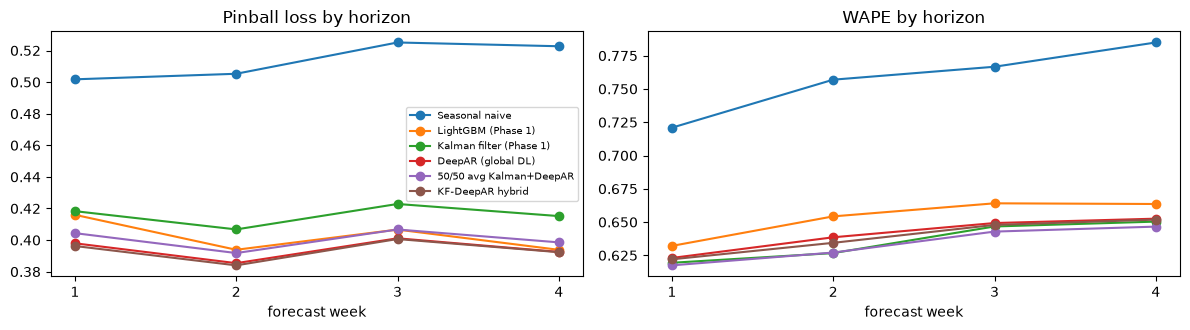

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for name, df in FCS.items():
    d = df.assign(week=(df.h - 1) // 7 + 1)
    r = summarise(d, "week")[0]
    ax[0].plot(r.index, r["Pinball"], marker="o", label=name)
    ax[1].plot(r.index, r["WAPE"], marker="o", label=name)
for a, t in zip(ax, ("Pinball loss", "WAPE")):
    a.set_xticks([1, 2, 3, 4]); a.set_xlabel("forecast week"); a.set_title(f"{t} by horizon")
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "06_by_horizon.png", dpi=150); plt.show()

## 6. Uncertainty: coverage vs sharpness
A good forecaster is **calibrated** (80% interval covers ≈80%) and, subject to that, **sharp** (narrow interval).
Note: sales are integers and often 0; when q10 = 0 every zero is "covered", so coverage of count forecasts tends to
sit above the nominal level even for a well-specified model.

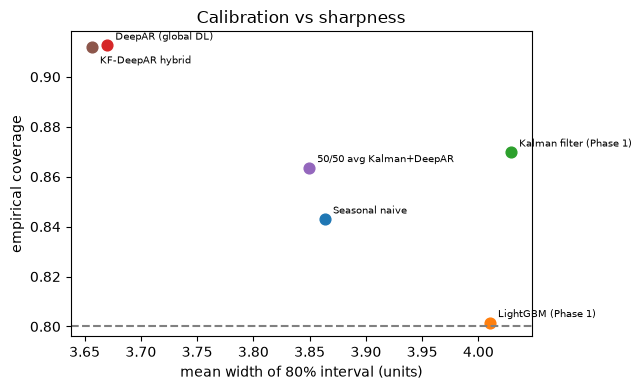

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for name in FCS:
    ax.scatter(main.loc[name, "Width80"], main.loc[name, "Cov80"], s=60)
    off = (6, -12) if name == "KF-DeepAR hybrid" else (6, 4)
    ax.annotate(name, (main.loc[name, "Width80"], main.loc[name, "Cov80"]), fontsize=7, xytext=off, textcoords="offset points")
ax.axhline(0.8, ls="--", c="grey"); ax.set_xlabel("mean width of 80% interval (units)"); ax.set_ylabel("empirical coverage")
ax.set_title("Calibration vs sharpness")
plt.tight_layout(); plt.savefig(FIG / "06_coverage_width.png", dpi=150); plt.show()

## 7. Is the hybrid significantly better? Paired bootstrap over SKUs
For each SKU: pinball loss averaged over origins, horizons and seeds. Difference = hybrid − other model
(negative = hybrid better). 95% CI from 5000 bootstrap resamples of SKUs.

In [9]:
def per_sku(df):
    d = df[df.y.notna()].copy()
    d["pin"] = np.mean([pinball(d.y.values, d[f"q{int(q*100)}"].values, q) for q in QUANTILES], axis=0)
    return d.groupby("sidx")["pin"].mean()


hyb = per_sku(FCS["KF-DeepAR hybrid"])
rng = np.random.default_rng(0)
sig = {}
for name, df in FCS.items():
    if name == "KF-DeepAR hybrid":
        continue
    diff = (hyb - per_sku(df)).values
    boot = np.array([rng.choice(diff, len(diff)).mean() for _ in range(5000)])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    sig[name] = dict(mean_diff=diff.mean(), ci_low=lo, ci_high=hi, hybrid_better_share=(diff < 0).mean(),
                     significant=("yes" if hi < 0 else "no (CI contains 0)" if lo <= 0 else "other model better"))
sig = pd.DataFrame(sig).T
sig.to_csv(TAB / "06_significance.csv"); sig

,mean_diff,ci_low,ci_high,hybrid_better_share,significant
Seasonal naive,-0.120394,-0.141241,-0.101384,0.94,yes
LightGBM (Phase 1),-0.009271,-0.014606,-0.004364,0.663333,yes
Kalman filter (Phase 1),-0.022465,-0.029842,-0.01612,0.846667,yes
DeepAR (global DL),-0.000941,-0.003702,0.001607,0.496667,no (CI contains 0)
50/50 avg Kalman+DeepAR,-0.007048,-0.009712,-0.004345,0.776667,yes


## 8. Export LaTeX tables for the report

In [10]:
def to_tex(df, path, caption, label):
    tex = df.to_latex(escape=True, column_format="l" + "c" * df.shape[1], caption=caption, label=label, position="t")
    (TAB / path).write_text(tex)


to_tex(pd.DataFrame(rows_fmt).T[["MAE", "RMSE", "WAPE", "Pinball", "Cov80"]], "main_results.tex",
       "Rolling-origin results (3 origins, 300 SKUs, 28-day horizon; DL models mean ± std over 3 seeds).", "tab:main")
to_tex(seg_p, "segment_pinball.tex", "Pinball loss by Syntetos--Boylan demand segment.", "tab:segment")
print("written:", sorted(p.name for p in TAB.glob("*.tex")))

written: ['main_results.tex', 'segment_pinball.tex']


## 9. Summary
The numbers above are the final results; the written interpretation is in the report (`report/main.tex`, Section VI).